# Box following demo

In [1]:
import importlib.util, json, math, statistics, subprocess, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import box_following as bf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEV = torch.device("cuda")
GB = 2**30
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 2070


/usr/local/lib/python3.12/dist-packages/torch/cuda/__init__.py:435: UserWarning: 
    Found GPU0 NVIDIA GeForce RTX 2070 which is of cuda capability 7.5.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (7.5) - (12.0)
    
  queued_call()
/usr/local/lib/python3.12/dist-packages/torch/cuda/__init__.py:435: UserWarning: 
    Please install PyTorch with a following CUDA
    configurations:  12.6 12.8 following instructions at
    https://pytorch.org/get-started/locally/
    
  queued_call()


Helpers.

In [2]:
def run_timed(fn, reps=10):
    fn()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats(DEV)
    base = torch.cuda.memory_allocated(DEV)
    times = []
    for _ in range(reps):
        start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        start.record(); fn(); end.record()
        torch.cuda.synchronize()
        times.append(start.elapsed_time(end))
    return statistics.median(times), torch.cuda.max_memory_allocated(DEV) - base


def nice_bytes(b):
    for unit in ("bytes", "KB", "MB", "GB"):
        if b < 1024:
            return f"{b:,.0f} {unit}" if unit == "bytes" else f"{b:,.1f} {unit}"
        b /= 1024
    return f"{b:,.1f} TB"

Other methods.

In [3]:
ittpd_dir = ROOT / "n_dims" / "ittpd"
sys.path.insert(0, str(ittpd_dir))
spec = importlib.util.spec_from_file_location("ittpd_transpose", ittpd_dir / "transpose.py")
ittpd = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ittpd)


def ittpd_passes(step):
    if step["mode"].startswith("linearize"):
        return 1
    return 3 if math.gcd(step["M"], step["K"]) > 1 else 2


def run_other(folder, SHAPE, PERM):
    out = subprocess.run([sys.executable, "benchmark.py", json.dumps(SHAPE), json.dumps(PERM)],
                         cwd=ROOT / "n_dims" / folder, capture_output=True, text=True)
    line = [l for l in out.stdout.splitlines() if l.startswith("{")][-1]
    return json.loads(line)

Run every method.

In [4]:
def run_case(SHAPE, PERM):
    OUT_SHAPE = tuple(SHAPE[p] for p in PERM)
    N = math.prod(SHAPE)
    TENSOR_BYTES = N * 4
    COPY_BYTES = 2 * TENSOR_BYTES
    results = {}

    def fresh():
        torch.manual_seed(0)
        return torch.randn(SHAPE, dtype=torch.float32, device=DEV)

    expected = fresh().permute(*PERM).contiguous()
    print(f"shape {SHAPE}, permutation {PERM}: {N:,} elements, {TENSOR_BYTES / GB:.2f} GB\n")

    # ---- box following: one time profiling
    t0 = time.perf_counter()
    plan = bf.plan_permute(SHAPE, PERM)
    plan_ms = (time.perf_counter() - t0) * 1e3
    t0 = time.perf_counter()
    prof = bf.profile(plan)
    torch.cuda.synchronize()
    upload_ms = (time.perf_counter() - t0) * 1e3

    print("BOX FOLLOWING")
    for i, s in enumerate(plan.steps, 1):
        print(f"  swap {i}: d_pre={s.d_pre}  rows={s.rows}  cols={s.cols}  d_post={s.d_post:,}")
    print(f"  planning time   {plan_ms:.2f} ms")
    print(f"  upload to GPU   {upload_ms:.2f} ms")
    print(f"  plan memory     {nice_bytes(prof.aux_bytes)}")

    # ---- box following: run, check in place and correct
    x = fresh()
    ptr_before, size_before = x.data_ptr(), x.untyped_storage().nbytes()
    bf.apply(x, prof)
    torch.cuda.synchronize()
    ptr_after, size_after = x.data_ptr(), x.untyped_storage().nbytes()
    box_correct = torch.equal(x.view(OUT_SHAPE), expected)
    print(f"  address         {ptr_before:#x} -> {ptr_after:#x}   same: {ptr_before == ptr_after}")
    print(f"  buffer size     {size_before:,} -> {size_after:,} bytes   same: {size_before == size_after}")
    print(f"  correct         {box_correct}")
    box_ms, box_extra = run_timed(lambda: bf.apply(x, prof))
    results["Box following (ours)"] = dict(ms=box_ms, aux=prof.aux_bytes + box_extra,
                                          in_place=ptr_before == ptr_after, correct=box_correct,
                                          passes=len(plan.steps), moved=plan.total_bytes_moved)
    del x

    # ---- .contiguous(): writes into a new tensor
    src = fresh().permute(*PERM)
    out = src.contiguous()
    cont_correct = torch.equal(out, expected)
    print("\n.contiguous()")
    print(f"  address         {src.data_ptr():#x} -> {out.data_ptr():#x}   same: {src.data_ptr() == out.data_ptr()}")
    print(f"  correct         {cont_correct}")
    del out
    cont_ms, cont_extra = run_timed(lambda: src.contiguous())
    results["PyTorch .contiguous()"] = dict(ms=cont_ms, aux=cont_extra, in_place=False, correct=cont_correct,
                                           passes=1, moved=COPY_BYTES)
    del src

    # ---- ITTPD
    cap = 0.05 * TENSOR_BYTES
    y = fresh()
    ptr_before = y.data_ptr()
    steps = ittpd.transpose_inplace(y, SHAPE, PERM, max_aux_bytes=cap)
    torch.cuda.synchronize()
    ittpd_n = sum(ittpd_passes(s) for s in steps)
    ittpd_correct = torch.equal(y.view(-1).view(OUT_SHAPE), expected)
    print("\nITTPD")
    print(f"  same address    {y.data_ptr() == ptr_before}")
    print(f"  correct         {ittpd_correct}")
    ittpd_ms, ittpd_extra = run_timed(lambda: ittpd.transpose_inplace(y, SHAPE, PERM, max_aux_bytes=cap))
    results["ITTPD"] = dict(ms=ittpd_ms, aux=ittpd_extra, in_place=y.data_ptr() == ptr_before,
                            correct=ittpd_correct, passes=ittpd_n, moved=ittpd_n * COPY_BYTES)
    del y, expected
    torch.cuda.empty_cache()   # give the GPU back before the other processes need it

    # ---- Gustavson and Gomez-Luna, each in its own process
    gv = run_other("gustavson", SHAPE, PERM)
    results["Gustavson"] = dict(ms=gv["gv_apply_ms"], aux=gv["gv_aux_bytes"], in_place=True,
                                correct=gv["gv_correct"], passes=gv["gv_passes"],
                                moved=gv["gv_passes"] * COPY_BYTES)
    gl = run_other("gomezluna", SHAPE, PERM)
    results["Gomez-Luna"] = dict(ms=gl["gl_apply_ms"], aux=gl["gl_aux_bytes"], in_place=True,
                                 correct=gl["gl_correct"], passes=gl["n_stages"],
                                 moved=gl["n_stages"] * COPY_BYTES)
    for name in ("Gustavson", "Gomez-Luna"):
        print(f"\n{name}\n  correct         {results[name]['correct']}")
    return results

Compare to baseline.

In [5]:
BASELINE = "PyTorch .contiguous()"
OURS, BASE, OTHER, INK, MUTED = "#2a78d6", "#7d7c78", "#c3c2b7", "#0b0b0b", "#52514e"


def show(results, SHAPE, PERM):
    base = results[BASELINE]
    copy_bytes = base["moved"]
    speedup = {n: base["ms"] / r["ms"] for n, r in results.items()}
    order = [BASELINE] + sorted((n for n in results if n != BASELINE), key=lambda n: results[n]["ms"])

    table = pd.DataFrame([
        {"Method": n,
         "Runtime (ms)": round(results[n]["ms"], 2),
         "Speedup vs baseline": "1.0x (baseline)" if n == BASELINE else f"{speedup[n]:.2f}x",
         "Passes": results[n]["passes"],
         "GB moved": round(results[n]["moved"] / GB, 2),
         "Data moved vs baseline": f"{results[n]['moved'] / copy_bytes:.2f}x",
         "Extra memory": nice_bytes(results[n]["aux"]),
         "In place": "yes" if results[n]["in_place"] else "no",
         "Correct": "yes" if results[n]["correct"] else "NO"}
        for n in order
    ]).set_index("Method")
    display(table)

    names = order[::-1]
    times = [results[n]["ms"] for n in names]
    colors = [OURS if n.startswith("Box") else BASE if n == BASELINE else OTHER for n in names]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.barh(names, times, color=colors, height=0.55)
    ax.set_xscale("log")
    ax.axvline(base["ms"], color=BASE, linestyle="--", linewidth=1)
    for i, (n, t) in enumerate(zip(names, times)):
        label = f"{t:.1f} ms" + ("  (baseline)" if n == BASELINE else f"  {speedup[n]:.2f}x")
        ax.text(max(t, base["ms"]) * 1.08, i, label, va="center", fontsize=9, color=INK)
    ax.set_xlabel("Runtime, ms (log scale, lower is better). Dashed line is the .contiguous() baseline.", color=MUTED)
    ax.set_title(f"shape {SHAPE}, permutation {PERM}", loc="left", fontsize=10, color=INK)
    ax.set_xlim(1, max(times) * 4)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(OTHER)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

Two 2 x 2 swaps.

In [6]:
SHAPE, PERM = (2, 2, 2, 2, 16777216), (1, 0, 3, 2, 4)
results = run_case(SHAPE, PERM)

shape (2, 2, 2, 2, 16777216), permutation (1, 0, 3, 2, 4): 268,435,456 elements, 1.00 GB

BOX FOLLOWING
  swap 1: d_pre=4  rows=2  cols=2  d_post=16,777,216
  swap 2: d_pre=1  rows=2  cols=2  d_post=67,108,864
  planning time   2.35 ms
  upload to GPU   4.77 ms
  plan memory     16 bytes


  address         0x739b90000000 -> 0x739b90000000   same: True
  buffer size     1,073,741,824 -> 1,073,741,824 bytes   same: True
  correct         True

.contiguous()
  address         0x739b90000000 -> 0x739af8000000   same: False
  correct         True



ITTPD
  same address    True
  correct         True



Gustavson
  correct         True

Gomez-Luna
  correct         True


,Runtime (ms),Speedup vs baseline,Passes,GB moved,Data moved vs baseline,Extra memory,In place,Correct
Method,,,,,,,,
PyTorch .contiguous(),7.00,1.0x (baseline),1,2.0,1.00x,1.0 GB,no,yes
Box following (ours),6.85,1.02x,2,2.0,1.00x,16 bytes,yes,yes
ITTPD,13.98,0.50x,2,4.0,2.00x,0 bytes,yes,yes
Gustavson,108.26,0.06x,2,4.0,2.00x,0 bytes,yes,yes
Gomez-Luna,333.91,0.02x,2,4.0,2.00x,16 bytes,yes,yes


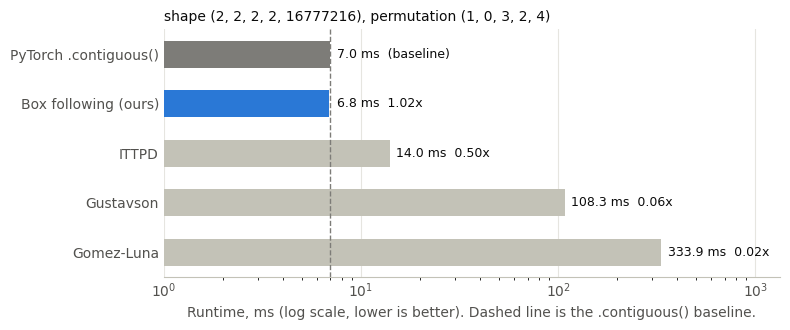

In [7]:
show(results, SHAPE, PERM)